# Deep Learning for Long/Short Equity Strategy (JPX Tokyo)
Based on the Kaggle JPX Tokyo Stock Exchange Prediction challenge, developed for an academic demonstration of an MLP (Multi-Layer Perceptron) model.

The data cleaning and initial feature engineering pipelines were developed by my project partner, see : https://www.kaggle.com/code/adncav/nettoyage-dataset

## 1. Environment Setup & Data Loading
We start by importing the necessary libraries and loading the preprocessed training (2017-2020) and validation (2021) datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

df_train = pd.read_parquet('/kaggle/input/notebooks/adncav/data-yim-nettoyage/jpx_train_cleaned_V2.parquet')
df_val = pd.read_parquet('/kaggle/input/notebooks/adncav/data-yim-nettoyage/jpx_val_cleaned.parquet')

print(f"Train loaded : {df_train.shape}")
print(f"Val loaded   : {df_val.shape}")

Train loaded : (1840370, 28)
Val loaded   : (451897, 28)


## 2. Feature Engineering

In [2]:
# Calculate candlestick shape features (shadows, ranges) and sector-relative returns for both datasets
# (initially just because candlesticks make me feel like a trader, but actually kinda helpful for the model).

for df_tmp in [df_train, df_val]:
    df_tmp['intraday_return'] = (df_tmp['Close'] - df_tmp['Open']) / (df_tmp['Open'] + 1e-8)
    df_tmp['intraday_range'] = (df_tmp['High'] - df_tmp['Low']) / (df_tmp['Open'] + 1e-8)
    df_tmp['upper_shadow'] = (df_tmp['High'] - df_tmp['Close']) / (df_tmp['Close'] + 1e-8)
    df_tmp['lower_shadow'] = (df_tmp['Close'] - df_tmp['Low']) / (df_tmp['Close'] + 1e-8)
    
    df_tmp['sector_return_20d'] = df_tmp.groupby(['Date', '17SectorCode'])['return_20d'].transform('mean')
    df_tmp['return_vs_sector_20d'] = df_tmp['return_20d'] - df_tmp['sector_return_20d']

cols_to_exclude = [
    'Date', 'SecuritiesCode', 'Target', 
    '33SectorCode', '17SectorCode', 'AdjustmentFactor',
    'Open', 'High', 'Low', 'Close', 'Volume'
]
features_cols = [c for c in df_train.columns if c not in cols_to_exclude]
print(f"Features ({len(features_cols)}) : {features_cols}")

# Group data by date, apply cross-sectional Z-score normalization, and convert to PyTorch tensors.
def build_daily_batches(df, features):

    daily_batches = []
    
    for date, group in df.groupby('Date', sort=True):
        X_day = group[features].values.astype(np.float32)
        y_day = group['Target'].values.astype(np.float32)
        
        X_day = np.nan_to_num(X_day, nan=0.0, posinf=0.0, neginf=0.0)
        y_day = np.nan_to_num(y_day, nan=0.0, posinf=0.0, neginf=0.0)
        
        X_mean = X_day.mean(axis=0, keepdims=True) # daily cross-sectional mean
        X_std = X_day.std(axis=0, keepdims=True) + 1e-8 # and std (without div. by 0)
        X_day_norm = np.clip((X_day - X_mean) / X_std, -5.0, 5.0) # normalization 
        
        X_tensor = torch.tensor(X_day_norm, dtype=torch.float32)
        y_tensor = torch.tensor(y_day, dtype=torch.float32).unsqueeze(1)
        
        daily_batches.append((date, X_tensor, y_tensor))
        
    return daily_batches

# Daily Information Coefficient (IC) + Long/Short portfolio returns based on ranked predictions.
def calculate_daily_metrics(preds, targets, weights, top_k=200):
    vx = preds - preds.mean()
    vy = targets - targets.mean()
    ic = torch.sum(vx * vy) / (torch.sqrt(torch.sum(vx**2) + 1e-8) * torch.sqrt(torch.sum(vy**2) + 1e-8))
    
    preds_np = preds.cpu().numpy().squeeze()
    targets_np = targets.cpu().numpy().squeeze()
    
    sorted_idx = np.argsort(preds_np)[::-1]
    top_ret = np.sum(targets_np[sorted_idx[:top_k]] * weights)
    bot_ret = np.sum(targets_np[sorted_idx[-top_k:][::-1]] * weights)
    
    portfolio_return = top_ret - bot_ret
    
    return ic.item(), portfolio_return

print("Building chronological daily batches...")
train_days = build_daily_batches(df_train, features_cols)
val_days = build_daily_batches(df_val, features_cols)

print(f"Training (2017-2020) : {len(train_days)} days.")
print(f"Validation    (2021) : {len(val_days)} days.")

Features (21) : ['return_1d', 'return_5d', 'return_20d', 'volatility_20d', 'close_to_sma20', 'volume_relative', 'market_return_1d', 'market_return_20d', 'return_vs_market_1d', 'market_dispersion_1d', 'market_breadth', 'return_1d_zscore', 'sector_return_1d', 'sector_return_20d', 'return_vs_sector_1d', 'return_vs_sector_20d', 'sector_vs_market_20d', 'intraday_return', 'intraday_range', 'upper_shadow', 'lower_shadow']
Building chronological daily batches...
Training (2017-2020) : 956 days.
Validation    (2021) : 226 days.


## 3. Model Architecture & Training Loop

In [3]:
# Information Coefficient
def daily_ranking_loss(preds, targets):
    vx = preds - torch.mean(preds)
    vy = targets - torch.mean(targets)
    
    corr = torch.sum(vx * vy) / (torch.sqrt(torch.sum(vx ** 2) + 1e-8) * torch.sqrt(torch.sum(vy ** 2) + 1e-8))
    return -corr 

# The MLP (the funny part)
class DailyQuantMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LayerNorm(64),
            nn.SiLU(),
            nn.Dropout(0.15), # NB: Good result with 0.30 while keeping second layer at 0.15
            
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.SiLU(),
            nn.Dropout(0.15),
            
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.network(x)


# Learning rate
torch.manual_seed(42)
model = DailyQuantMLP(len(features_cols)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-2)
EPOCHS = 200
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)


best_sharpe = -999.0

print("Starting daily cross-sectional training...\n")

# Execute the day-by-day training loop and evaluate the Long/Short portfolio Sharpe ratio on the validation set.
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_ic_list = []

    # Training
    for date, X_day, y_day in train_days:
        X_day, y_day = X_day.to(device), y_day.to(device)
        
        optimizer.zero_grad()
        preds_day = model(X_day)
        loss = daily_ranking_loss(preds_day, y_day)
        loss.backward()
        optimizer.step()
        
        train_ic_list.append(-loss.item())
        
    mean_train_ic = np.mean(train_ic_list)
    scheduler.step()

    # Assessment
    model.eval()
    val_ic_list = []
    daily_returns_2021 = []
    
    weights = np.linspace(2, 1, 200)
    weights /= weights.sum()
    
    with torch.no_grad():
        for date, X_day, y_day in val_days:
            X_day, y_day = X_day.to(device), y_day.to(device)
            preds_day = model(X_day)
            
            ic, daily_return = calculate_daily_metrics(preds_day, y_day, weights)

            val_ic_list.append(ic)
            daily_returns_2021.append(daily_return)
            
    mean_val_ic = np.mean(val_ic_list)
    daily_returns_2021 = np.array(daily_returns_2021)
    current_sharpe = daily_returns_2021.mean() / (daily_returns_2021.std() + 1e-8)

    # Stats
    if current_sharpe > best_sharpe:
        best_sharpe = current_sharpe
        torch.save(model.state_dict(), 'best_daily_mlp.pth')
        saved_flag = "--> [MODEL SAVED]"
    else:
        saved_flag = ""
        
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train IC: {mean_train_ic:+.5f} | Val IC: {mean_val_ic:+.5f} | Val Sharpe: {current_sharpe:+.4f} {saved_flag}")

print(f"\nTraining completed! Best 2021 Validation Sharpe Ratio: {best_sharpe:+.4f}")

Starting daily cross-sectional training...

Epoch 01/200 | Train IC: +0.01155 | Val IC: -0.00103 | Val Sharpe: -0.0439 --> [MODEL SAVED]
Epoch 02/200 | Train IC: +0.01509 | Val IC: -0.00019 | Val Sharpe: -0.0308 --> [MODEL SAVED]
Epoch 03/200 | Train IC: +0.01650 | Val IC: +0.00031 | Val Sharpe: -0.0268 --> [MODEL SAVED]
Epoch 04/200 | Train IC: +0.01759 | Val IC: +0.00076 | Val Sharpe: -0.0207 --> [MODEL SAVED]
Epoch 05/200 | Train IC: +0.01790 | Val IC: +0.00064 | Val Sharpe: -0.0194 --> [MODEL SAVED]
Epoch 06/200 | Train IC: +0.01843 | Val IC: +0.00109 | Val Sharpe: -0.0171 --> [MODEL SAVED]
Epoch 07/200 | Train IC: +0.01958 | Val IC: +0.00121 | Val Sharpe: -0.0158 --> [MODEL SAVED]
Epoch 08/200 | Train IC: +0.02007 | Val IC: +0.00127 | Val Sharpe: -0.0159 
Epoch 09/200 | Train IC: +0.02035 | Val IC: +0.00118 | Val Sharpe: -0.0168 
Epoch 10/200 | Train IC: +0.02048 | Val IC: +0.00165 | Val Sharpe: -0.0119 --> [MODEL SAVED]
Epoch 11/200 | Train IC: +0.02016 | Val IC: +0.00174 | Val S

## 4. Performance Assessment & Model Decay
Evaluate the best model on the 2021 validation set and visualize cumulative portfolio returns and model decay.


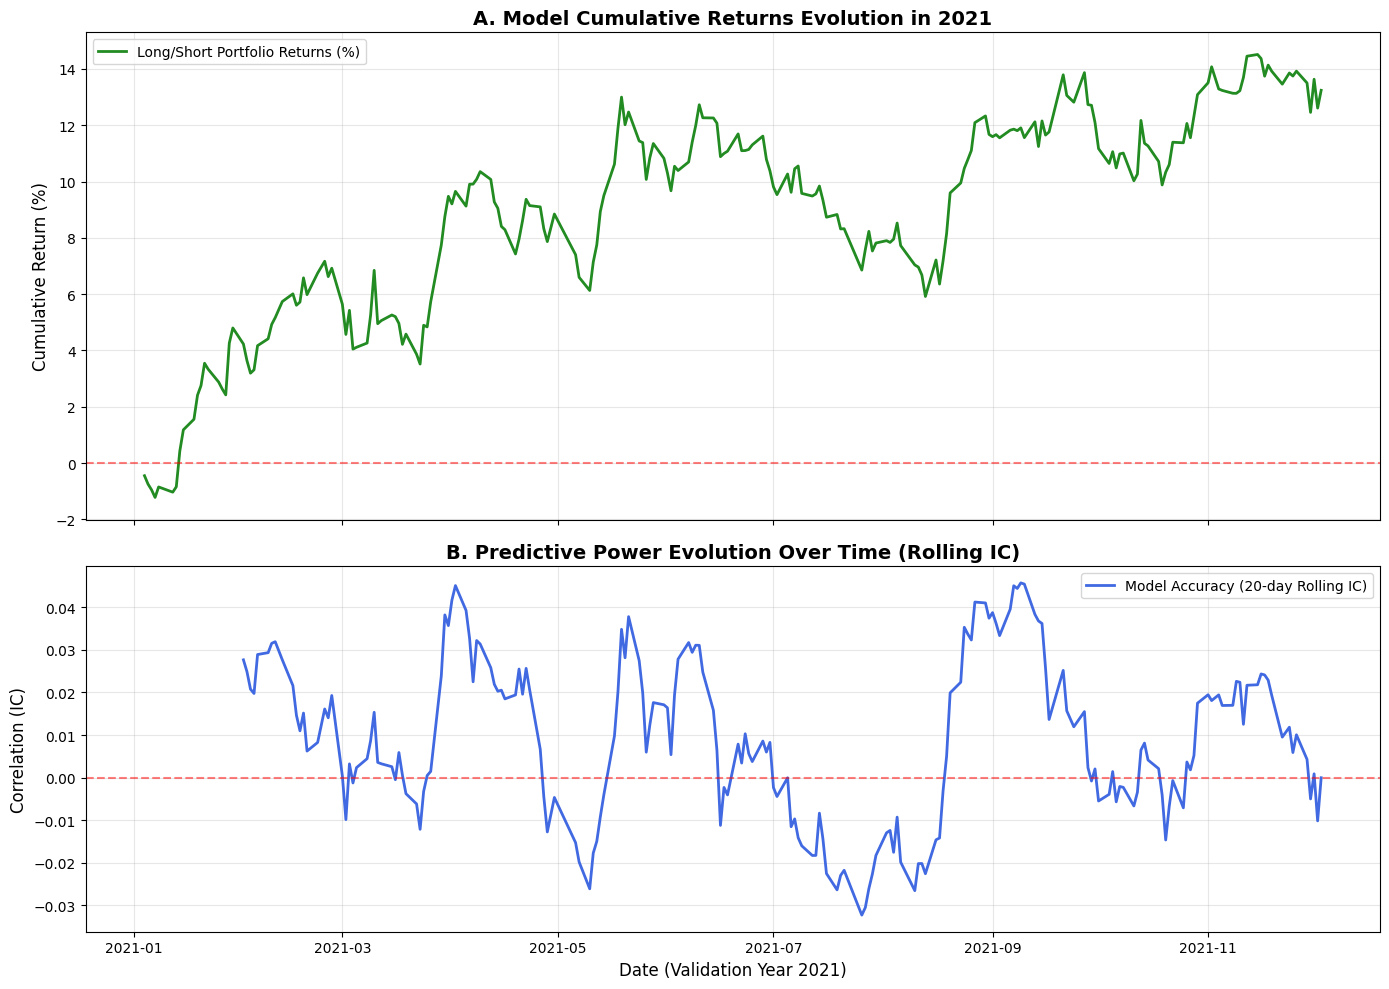

In [4]:
model.load_state_dict(torch.load('best_daily_mlp.pth'))
model.eval()

dates_list = []
daily_ic_list = []
daily_returns_list = []

# Linearly decaying weights for the top/bottom 200 portfolio allocation
weights = np.linspace(2, 1, 200)
weights /= weights.sum()

# Generate predictions and calculate metrics
with torch.no_grad():
    for date, X_day, y_day in val_days:
        X_day, y_day = X_day.to(device), y_day.to(device)
        
        preds_day = model(X_day)
        ic, daily_return = calculate_daily_metrics(preds_day, y_day, weights)

        dates_list.append(date)
        daily_ic_list.append(ic)
        daily_returns_list.append(daily_return)
        
# Results DataFrame
df_plot = pd.DataFrame({
    'Date': pd.to_datetime(dates_list),
    'Daily_IC': daily_ic_list,
    'Daily_Return': daily_returns_list
})

df_plot['Cumulative_Return'] = df_plot['Daily_Return'].cumsum() * 100 
df_plot['Rolling_IC_20d'] = df_plot['Daily_IC'].rolling(window=20).mean()

# Visualization
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

# Plot A: Cumulative Returns
ax1.plot(df_plot['Date'], df_plot['Cumulative_Return'], color='forestgreen', linewidth=2, label='Long/Short Portfolio Returns (%)')
ax1.axhline(0, color='red', linestyle='--', alpha=0.5)
ax1.set_title('A. Model Cumulative Returns Evolution in 2021', fontsize=14, fontweight='bold')
ax1.set_ylabel('Cumulative Return (%)', fontsize=12)
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Plot B: Model Decay (Rolling IC)
ax2.plot(df_plot['Date'], df_plot['Rolling_IC_20d'], color='royalblue', linewidth=2, label='Model Accuracy (20-day Rolling IC)')
ax2.axhline(0, color='red', linestyle='--', alpha=0.5)
ax2.set_title('B. Predictive Power Evolution Over Time (Rolling IC)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Correlation (IC)', fontsize=12)
ax2.set_xlabel('Date (Validation Year 2021)', fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()